# 05 · One-stage anchor-free detector: YOLO11

YOLO11 (Ultralytics, COCO-pretrained) predicts boxes from grid points, without anchor boxes.
Starting point: the baseline of notebook 02 (YOLO11s, 1280 px). It peaked after 2 of 12 epochs, so the tuning runs here use
**6 epochs**, and the reference is re-trained with the same 6 epochs.

Tuned parameters: an **extra high-resolution detection head (P2, stride 4)** and the **input resolution** (1536 px).

**Run:** Kaggle (GPU T4, Internet ON, inputs: competition + notebook 01 output; optionally notebooks 03/04 outputs for the comparison)
or Google Colab (T4, Colab secret `KAGGLE_API_TOKEN`).

In [1]:
# environment: Kaggle (data attached as inputs) or Google Colab (data downloaded with the Kaggle API)
import os, sys, subprocess
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
COMP = "multiple-object-video-detection-hw-2-ucu-ai-2026"
if IN_COLAB:
    # needs the Colab secret KAGGLE_API_TOKEN (Kaggle → Settings → API → Generate New Token)
    from google.colab import userdata, drive
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    drive.mount("/content/drive")                                   # outputs go to Google Drive, so they survive a disconnect
    INPUT, WORK = Path("/content/input"), Path("/content/drive/MyDrive/visdrone_hw2")
    subprocess.run("pip install -q -U kaggle pycocotools", shell=True, check=True)
    if not (INPUT / "comp" / "test_images.csv").exists():
        (INPUT / "comp").mkdir(parents=True, exist_ok=True)
        subprocess.run(f"kaggle competitions download -c {COMP} -p {INPUT / 'comp'} && cd {INPUT / 'comp'} "
                       "&& unzip -q -o '*.zip' && rm -f *.zip", shell=True, check=True)
else:
    INPUT, WORK = Path("/kaggle/input"), Path("/kaggle/working")
    subprocess.run("pip install -q pycocotools", shell=True)
WORK.mkdir(parents=True, exist_ok=True); os.chdir(WORK)
print("Colab" if IN_COLAB else "Kaggle", "| outputs ->", WORK)

Kaggle | outputs -> /kaggle/working


In [2]:
%%writefile vd_utils.py
"""Shared helpers for the VisDrone-VID homework: data loading, COCO evaluation, submission writing."""
import json
from pathlib import Path

import numpy as np
import pandas as pd

CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]


def find_data_root(start="/kaggle/input"):
    """Folder that contains train/, val/ and test/ (found by its train/annotations_coco.json)."""
    hits = sorted(Path(start).glob("**/train/annotations_coco.json"))
    if not hits:
        raise FileNotFoundError(f"train/annotations_coco.json not found under {start}: attach the competition data")
    return hits[0].parent.parent


def load_split(root, split):
    """COCO json of one split -> (images, annotations) DataFrames with 0-based `cls` and pixel boxes."""
    root = Path(root)
    coco = json.loads((root / split / "annotations_coco.json").read_text())
    imgs = pd.DataFrame(coco["images"]).rename(columns={"id": "image_id"})
    if "video" in imgs:
        imgs["clip"] = imgs["video"].astype(str)
    else:
        imgs["clip"] = imgs["file_name"].map(lambda f: Path(f).parent.name)
    imgs["path"] = [_image_path(root, split, f) for f in imgs["file_name"]]

    anns = pd.DataFrame(coco["annotations"])
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns["iscrowd"] = anns.get("iscrowd", 0)
    anns["cls"] = anns["category_id"] - 1
    anns = anns.merge(imgs[["image_id", "clip", "width", "height"]], on="image_id")
    return imgs, anns


def _image_path(root, split, file_name):
    for p in (root / split / file_name, root / split / "images" / file_name, root / file_name):
        if p.exists():
            return str(p)
    raise FileNotFoundError(f"image {file_name} not found in {root / split}")


def coco_eval(gt_json, dets, img_ids=None, cat_ids=None, verbose=False):
    """COCO mAP with ignored regions (iscrowd=1) skipped and up to 500 detections per image.

    dets: list of dicts {image_id, category_id (1-based), bbox [x, y, w, h], score}.
    """
    import contextlib, io
    from pycocotools.coco import COCO
    from pycocotools.cocoeval import COCOeval

    quiet = contextlib.redirect_stdout(io.StringIO()) if not verbose else contextlib.nullcontext()
    with quiet:
        gt = COCO(str(gt_json))
        if not dets:
            return {k: 0.0 for k in ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]}
        dt = gt.loadRes(dets)
        E = COCOeval(gt, dt, "bbox")
        E.params.maxDets = [1, 100, 500]
        if img_ids is not None:
            E.params.imgIds = list(img_ids)
        if cat_ids is not None:
            E.params.catIds = list(cat_ids)
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    out = {k: float(v) for k, v in zip(["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"], s[:6])}
    # per-class AP[.5:.95] from the same evaluation: precision has shape [IoU, recall, class, area, maxDets]
    prec = E.eval["precision"][:, :, :, 0, -1]
    for k, cat in enumerate(E.params.catIds):
        p = prec[:, :, k]
        out[f"AP_{CLASSES[cat - 1]}"] = float(p[p > -1].mean()) if (p > -1).any() else float("nan")
    return out


def write_submission(dets, test_csv, out_path, max_dets=500):
    """dets: dict image_id (str, e.g. clip_001_0000001) -> array N x 6 [cls, score, x, y, w, h] in pixels."""
    test = pd.read_csv(test_csv)
    rows = []
    for image_id in test["image_id"]:
        d = np.asarray(dets.get(image_id, np.zeros((0, 6))), dtype=float).reshape(-1, 6)
        d = d[np.argsort(-d[:, 1])][:max_dets]
        rows.append(" ".join(f"{int(c)} {s:.4f} {x:.1f} {y:.1f} {w:.1f} {h:.1f}" for c, s, x, y, w, h in d))
    sub = pd.DataFrame({"image_id": test["image_id"], "PredictionString": rows})
    sub.to_csv(out_path, index=False)
    return sub


def build_yolo(root, out, step=4):
    """Same conversion as notebook 01: every `step`-th train frame, all val frames, ignored regions painted grey (114),
    boxes whose centre lies in an ignored region dropped. Used when notebook 01's output is not available (e.g. Colab)."""
    import shutil
    from PIL import Image
    out = Path(out)
    for split, st in [("train", step), ("val", 1)]:
        imgs, anns = load_split(root, split)
        (out / "images" / split).mkdir(parents=True, exist_ok=True); (out / "labels" / split).mkdir(parents=True, exist_ok=True)
        im = imgs.sort_values(["clip", "frame_id"]); im = im[im.groupby("clip").cumcount() % st == 0]
        by_img = dict(tuple(anns.groupby("image_id")))
        for r in im.itertuples():
            a = by_img.get(r.image_id, anns.iloc[:0])
            ig = a.loc[a.iscrowd == 1, ["x", "y", "w", "h"]].values; ob = a[a.iscrowd == 0]
            name = f"{r.clip}_{Path(r.file_name).stem}"; dst = out / "images" / split / f"{name}.jpg"
            if len(ig):
                px = np.array(Image.open(r.path).convert("RGB"))
                for x, y, w, h in ig.round().astype(int):
                    px[max(y, 0):y + h, max(x, 0):x + w] = 114
                Image.fromarray(px).save(dst, quality=95)
                cx, cy = (ob.x + ob.w / 2).values, (ob.y + ob.h / 2).values
                inside = ((cx[:, None] >= ig[:, 0]) & (cx[:, None] <= ig[:, 0] + ig[:, 2]) &
                          (cy[:, None] >= ig[:, 1]) & (cy[:, None] <= ig[:, 1] + ig[:, 3])).any(1)
                ob = ob[~inside]
            else:
                shutil.copy(r.path, dst)
            lines = [f"{c} {(x + w / 2) / r.width:.6f} {(y + h / 2) / r.height:.6f} {w / r.width:.6f} {h / r.height:.6f}"
                     for c, x, y, w, h in zip(ob.cls, ob.x, ob.y, ob.w, ob.h)]
            (out / "labels" / split / f"{name}.txt").write_text("\n".join(lines))
    (out / "data.yaml").write_text(f"path: {out}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(CLASSES))}\n")
    return out

Writing vd_utils.py


In [3]:
subprocess.run("pip install -q ultralytics", shell=True, check=True)
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import gc, json, random, time
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from ultralytics import YOLO
import vd_utils as vd

SEED = 42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT = vd.find_data_root(INPUT)
LOCAL = Path("/content/vd_yolo") if IN_COLAB else WORK / "vd_yolo"
hits = sorted(INPUT.glob("**/vd_yolo/data.yaml")) + sorted(LOCAL.parent.glob("vd_yolo/data.yaml"))
YOLO_DIR = hits[0].parent if hits else vd.build_yolo(ROOT, LOCAL, step=4)
DATA_YAML = WORK / "data.yaml"
DATA_YAML.write_text(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames: {dict(enumerate(vd.CLASSES))}\n")
val_imgs, _ = vd.load_split(ROOT, "val")
VAL_GT = ROOT / "val" / "annotations_coco.json"
DEVICE = 0 if torch.cuda.is_available() else "cpu"

def find_file(rel):
    hits = sorted(WORK.glob(rel)) + sorted(INPUT.glob(f"**/{rel}"))
    return hits[0] if hits else None
print("yolo dataset:", YOLO_DIR)

yolo dataset: /kaggle/input/notebooks/yarema1234/notebook0f34d49e70/vd_yolo


## 1. How YOLO11 assigns locations to objects (no anchors)
Every cell of the stride-8/16/32 feature maps is an *anchor point*. For each object, the **task-aligned assigner** (TOOD)
considers the points that lie inside the box, scores each by `cls_score^α · IoU^β` of its current prediction, and keeps the
top-k (k = 10) as positives; the box is regressed as distances to its four sides (with Distribution Focal Loss) plus a CIoU loss.

Consequence for this data: an object of 10 px covers about **one** point of the stride-8 map (at most a couple), so it gets very few
candidate positives, and neighbouring small objects compete for the same points. A **P2 head (stride 4)** gives each small object ~4×
more points; a larger input (1536 px) makes objects bigger in pixels. These are the two parameters tuned below.

In [4]:
# a YOLO11 variant with an additional stride-4 (P2) detection head, written in the Ultralytics model format
P2_YAML = WORK / "yolo11-p2.yaml"
P2_YAML.write_text("""
nc: 8
scales:
  s: [0.50, 0.50, 1024]
backbone:
  - [-1, 1, Conv, [64, 3, 2]]          # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]         # 1-P2/4
  - [-1, 2, C3k2, [256, False, 0.25]]  # 2
  - [-1, 1, Conv, [256, 3, 2]]         # 3-P3/8
  - [-1, 2, C3k2, [512, False, 0.25]]  # 4
  - [-1, 1, Conv, [512, 3, 2]]         # 5-P4/16
  - [-1, 2, C3k2, [512, True]]         # 6
  - [-1, 1, Conv, [1024, 3, 2]]        # 7-P5/32
  - [-1, 2, C3k2, [1024, True]]        # 8
  - [-1, 1, SPPF, [1024, 5]]           # 9
  - [-1, 2, C2PSA, [1024]]             # 10
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 2, C3k2, [512, False]]        # 13
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 2, C3k2, [256, False]]        # 16 (P3/8)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]]
  - [-1, 2, C3k2, [128, False]]        # 19 (P2/4, new)
  - [-1, 1, Conv, [128, 3, 2]]
  - [[-1, 16], 1, Concat, [1]]
  - [-1, 2, C3k2, [256, False]]        # 22 (P3/8)
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 13], 1, Concat, [1]]
  - [-1, 2, C3k2, [512, False]]        # 25 (P4/16)
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 10], 1, Concat, [1]]
  - [-1, 2, C3k2, [1024, True]]        # 28 (P5/32)
  - [[19, 22, 25, 28], 1, Detect, [nc]]
""")

1319

## 2. Experiments (same data, validation and evaluation as all other models)
| name | change | search range / why |
|---|---|---|
| `yolo_s1280_e6` | YOLO11s, 1280 px, 6 epochs | reference under the tuning budget |
| `yolo_p2_1280_e6` | + P2 head (stride 4) | {P3–P5, P2–P5}: more locations for small objects |
| `yolo_s1536_e6` | input 1536 px | {1280, 1536}: objects 1.2× larger in pixels |

All runs: SGD default schedule, cosine LR, mosaic off for the last epoch, default YOLO augmentation, seed 42.
Ultralytics accumulates gradients to a nominal batch of 64, so the smaller batch of the heavier runs does not change the effective batch.

In [5]:
BASE = dict(model="yolo11s.pt", imgsz=1280, epochs=6, batch=8, cos_lr=True, close_mosaic=1, seed=SEED, workers=4 if not IN_COLAB else 2,
            device=DEVICE, project=str(WORK / "yolo_runs"), exist_ok=True, plots=True)
EXPS = {
    "yolo_s1280_e6": {},
    "yolo_p2_1280_e6": dict(model=str(P2_YAML), batch=4),
    "yolo_s1536_e6": dict(imgsz=1536, batch=4),
}

def predict(model, paths, imgsz, conf=0.001, iou=0.6, bs=4):
    # {path: array N x 6 [cls, score, x, y, w, h]} in original pixels; small explicit chunks avoid GPU OOM
    out, t0 = {}, time.time()
    for k in range(0, len(paths), bs):
        for r in model.predict(paths[k:k + bs], imgsz=imgsz, conf=conf, iou=iou, max_det=500, verbose=False):
            b = r.boxes; xyxy = b.xyxy.cpu().numpy()
            out[r.path] = np.c_[b.cls.cpu().numpy(), b.conf.cpu().numpy(), xyxy[:, :2], xyxy[:, 2:] - xyxy[:, :2]]
    return out, (time.time() - t0) / len(paths) * 1000

def to_coco(preds, imgs):
    pid = dict(zip(imgs["path"], imgs["image_id"]))
    return [{"image_id": int(pid[p]), "category_id": int(c) + 1, "bbox": [float(x), float(y), float(w), float(h)], "score": float(s)}
            for p, d in preds.items() for c, s, x, y, w, h in d]

RESULTS, CURVES = {}, {}
for name, change in EXPS.items():
    cfg = {**BASE, **change}
    best = find_file(f"yolo_runs/{name}/weights/best.pt")
    if best is None:
        t0 = time.time()
        model = YOLO(cfg["model"])
        if cfg["model"].endswith(".yaml"):
            model = model.load("yolo11s.pt")                                   # COCO weights for every layer that matches
        model.train(data=str(DATA_YAML), name=name, **{k: v for k, v in cfg.items() if k != "model"})
        train_min = (time.time() - t0) / 60
        best = WORK / "yolo_runs" / name / "weights" / "best.pt"
        del model; gc.collect(); torch.cuda.empty_cache()
    else:
        print("reusing", best); train_min = np.nan
    rc = best.parent.parent / "results.csv"
    if rc.exists(): CURVES[name] = pd.read_csv(rc)
    model = YOLO(best)
    preds, ms = predict(model, val_imgs["path"].tolist(), imgsz=cfg["imgsz"])
    RESULTS[name] = {**vd.coco_eval(VAL_GT, to_coco(preds, val_imgs)), "ms / image (incl. disk)": ms, "train min": train_min}
    del model; gc.collect(); torch.cuda.empty_cache()
    pd.DataFrame(RESULTS).T.to_csv(WORK / "results_yolo.csv")

R = pd.DataFrame(RESULTS).T
MAIN = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "ms / image (incl. disk)", "train min"]
display(R[MAIN].astype(float).round(4))
display(R[[f"AP_{c}" for c in vd.CLASSES]].T.astype(float).round(3))

Using 6072 train, 2846 val images for fraction=1.0 at imgsz=1280
                   all       2846     112903      0.482      0.406      0.378      0.189
                   all       2846     112903      0.509      0.429      0.427      0.214
                   all       2846     112903      0.536      0.411      0.404      0.203
                   all       2846     112903      0.491       0.43      0.403      0.204
                   all       2846     112903      0.525      0.434      0.421      0.218
                   all       2846     112903      0.524      0.424      0.404      0.209
6 epochs completed in 0.697 hours.
                   all       2846     112903      0.523      0.435      0.421      0.218
                person       2776      49486      0.699       0.68      0.695      0.296
               bicycle        982       6020      0.509      0.403      0.407      0.188
                   car       2382      31740      0.735      0.666      0.652      0.409
... (27 li

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,ms / image (incl. disk),train min
yolo_s1280_e6,0.2026,0.3972,0.1809,0.1198,0.2034,0.3159,98.5794,47.4670
yolo_p2_1280_e6,0.2039,0.4176,0.1758,0.1220,0.1915,0.3427,107.2248,68.3354
yolo_s1536_e6,0.2173,0.4233,0.1969,0.1139,0.2073,0.3443,83.9074,59.0450


,yolo_s1280_e6,yolo_p2_1280_e6,yolo_s1536_e6
AP_person,0.288,0.282,0.292
AP_bicycle,0.170,0.208,0.245
AP_car,0.401,0.401,0.414
AP_van,0.161,0.166,0.181
AP_truck,0.282,0.137,0.166
AP_tricycle,0.189,0.220,0.196
AP_bus,0.022,0.088,0.119
AP_motor,0.115,0.136,0.131


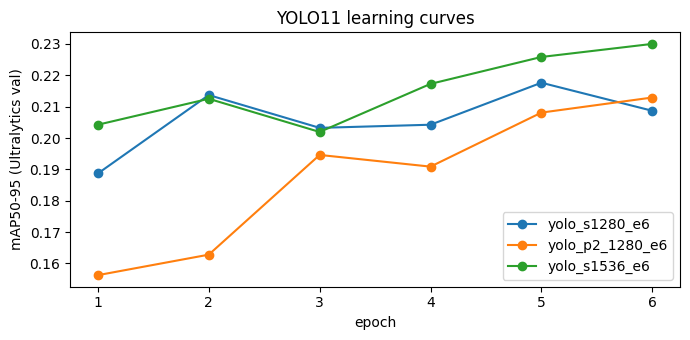

In [6]:
# per-epoch validation mAP logged by Ultralytics (on the masked val frames; the table above is the official metric)
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, c in CURVES.items():
    c.columns = c.columns.str.strip()
    ax.plot(c["epoch"], c["metrics/mAP50-95(B)"], marker="o", label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("mAP50-95 (Ultralytics val)"); ax.legend(); ax.set_title("YOLO11 learning curves")
plt.tight_layout(); plt.savefig(WORK / "curves_yolo.png", dpi=120); plt.show()

## 3. Comparison with the tuned anchor-based detectors, by object size
Uses the result tables of notebooks 03 and 04 if their outputs are attached.

In [7]:
rows = [R]
for f, tag in [("results_03.csv", "two-stage"), ("results_retina.csv", "one-stage anchor-based")]:
    p = find_file(f)
    if p is not None:
        T = pd.read_csv(p, index_col=0); b = T["mAP"].astype(float).idxmax()
        rows.append(T.loc[[b]].rename(index={b: f"{b} (tuned {tag})"}))
cmp_cols = ["mAP", "AP50", "AP_small", "AP_medium", "AP_large"]
display(pd.concat(rows)[cmp_cols].astype(float).round(4).sort_values("mAP", ascending=False))

,mAP,AP50,AP_small,AP_medium,AP_large
frcnn_base (tuned two-stage),0.2245,0.4584,0.1046,0.2057,0.4166
yolo_s1536_e6,0.2173,0.4233,0.1139,0.2073,0.3443
yolo_p2_1280_e6,0.2039,0.4176,0.1220,0.1915,0.3427
yolo_s1280_e6,0.2026,0.3972,0.1198,0.2034,0.3159


## 4. Test submission with the best YOLO11 run

In [8]:
BEST = R["mAP"].astype(float).idxmax(); print("best:", BEST)
model = YOLO(find_file(f"yolo_runs/{BEST}/weights/best.pt"))
test = pd.read_csv(ROOT / "test_images.csv"); test["path"] = [str(ROOT / f) for f in test["file_name"]]
tp, _ = predict(model, test["path"].tolist(), imgsz={**BASE, **EXPS[BEST]}["imgsz"])
dets = {i: tp.get(p, np.zeros((0, 6))) for i, p in zip(test["image_id"], test["path"])}
vd.write_submission(dets, ROOT / "test_images.csv", WORK / "submission_yolo.csv")
print("written submission_yolo.csv")

best: yolo_s1536_e6
written submission_yolo.csv
